# Co wykorzystują regresja i XGBoost?
Uruchom **Run All** w `.venv`. Ten notebook nie uruchamia AST. Wymaga wyników poprzedniej analizy obu paczek. Porównuje ważność cech na odłożonych płytkach i osobne modele kontrolne uczone na tle. Nie dobiera automatycznie nowego modelu produkcyjnego.

In [1]:
from pathlib import Path
import sys, json
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p/'config/client_archive_manifest.json').exists()), None)
if ROOT is None: raise FileNotFoundError('Otwórz folder ceramic-ping-lab.')
sys.path.insert(0, str(ROOT/'src'))
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown, Audio
from pinglab.clientstudy import OUT_REL, decode, load
from pinglab.clientexplanations import importances, controls
OUT = ROOT/OUT_REL/'explanations'
%matplotlib inline
RECOMPUTE = True
print(sys.executable)

/Users/karolsii/dev/ceramic-ping-lab/.venv/bin/python


## 1. Jedno uderzenie → cechy → ocena → mediana serii
170 ms = 20 ms przed +150 ms po początku. Jeden wiersz ma 26 MFCC, 15 physics albo ich połączenie: 41 cech. Każdy model uczy się etykiet uderzeń na trzech płytkach; dwie całe inne płytki są testowe. Powtarzamy sześć podziałów. Dziesięć uderzeń na plik daje 270 wierszy. Seria nie trafia do modelu jako sekwencja: agregujemy dopiero jego oceny. AST jest wyłącznie punktem odniesienia w notebooku 03.

In [2]:
splits = json.loads((ROOT/OUT_REL/'split_audit.json').read_text())
display(pd.DataFrame(splits)[['fold','train_groups','test_groups','train_taps','test_taps']])

,fold,train_groups,test_groups,train_taps,test_taps
0,Bad_1__OK_1,"[Bad_2, OK_2, OK_3]","[Bad_1, OK_1]",130,140
1,Bad_1__OK_2,"[Bad_2, OK_1, OK_3]","[Bad_1, OK_2]",200,70
2,Bad_1__OK_3,"[Bad_2, OK_1, OK_2]","[Bad_1, OK_3]",180,90
3,Bad_2__OK_1,"[Bad_1, OK_2, OK_3]","[Bad_2, OK_1]",120,150
4,Bad_2__OK_2,"[Bad_1, OK_1, OK_3]","[Bad_2, OK_2]",190,80
5,Bad_2__OK_3,"[Bad_1, OK_1, OK_2]","[Bad_2, OK_3]",170,100


## 2. Co się psuje po zaburzeniu jednej cechy?
Przenosimy cechę między całymi profilami nagrań testowych, po 10 tapów, 30 losowań. Mierzymy wzrost log-loss i spadek balanced accuracy. Cechy skorelowane mogą się zastępować, a nietypowe kombinacje mogą zawyżać wpływ. Ranking opisuje model w tym zbiorze, nie fizyczną przyczynę pęknięcia. Wyniki podziałów nie są niezależne.

Importance: Bad_1__OK_1
Importance: Bad_1__OK_2
Importance: Bad_1__OK_3
Importance: Bad_2__OK_1
Importance: Bad_2__OK_2
Importance: Bad_2__OK_3


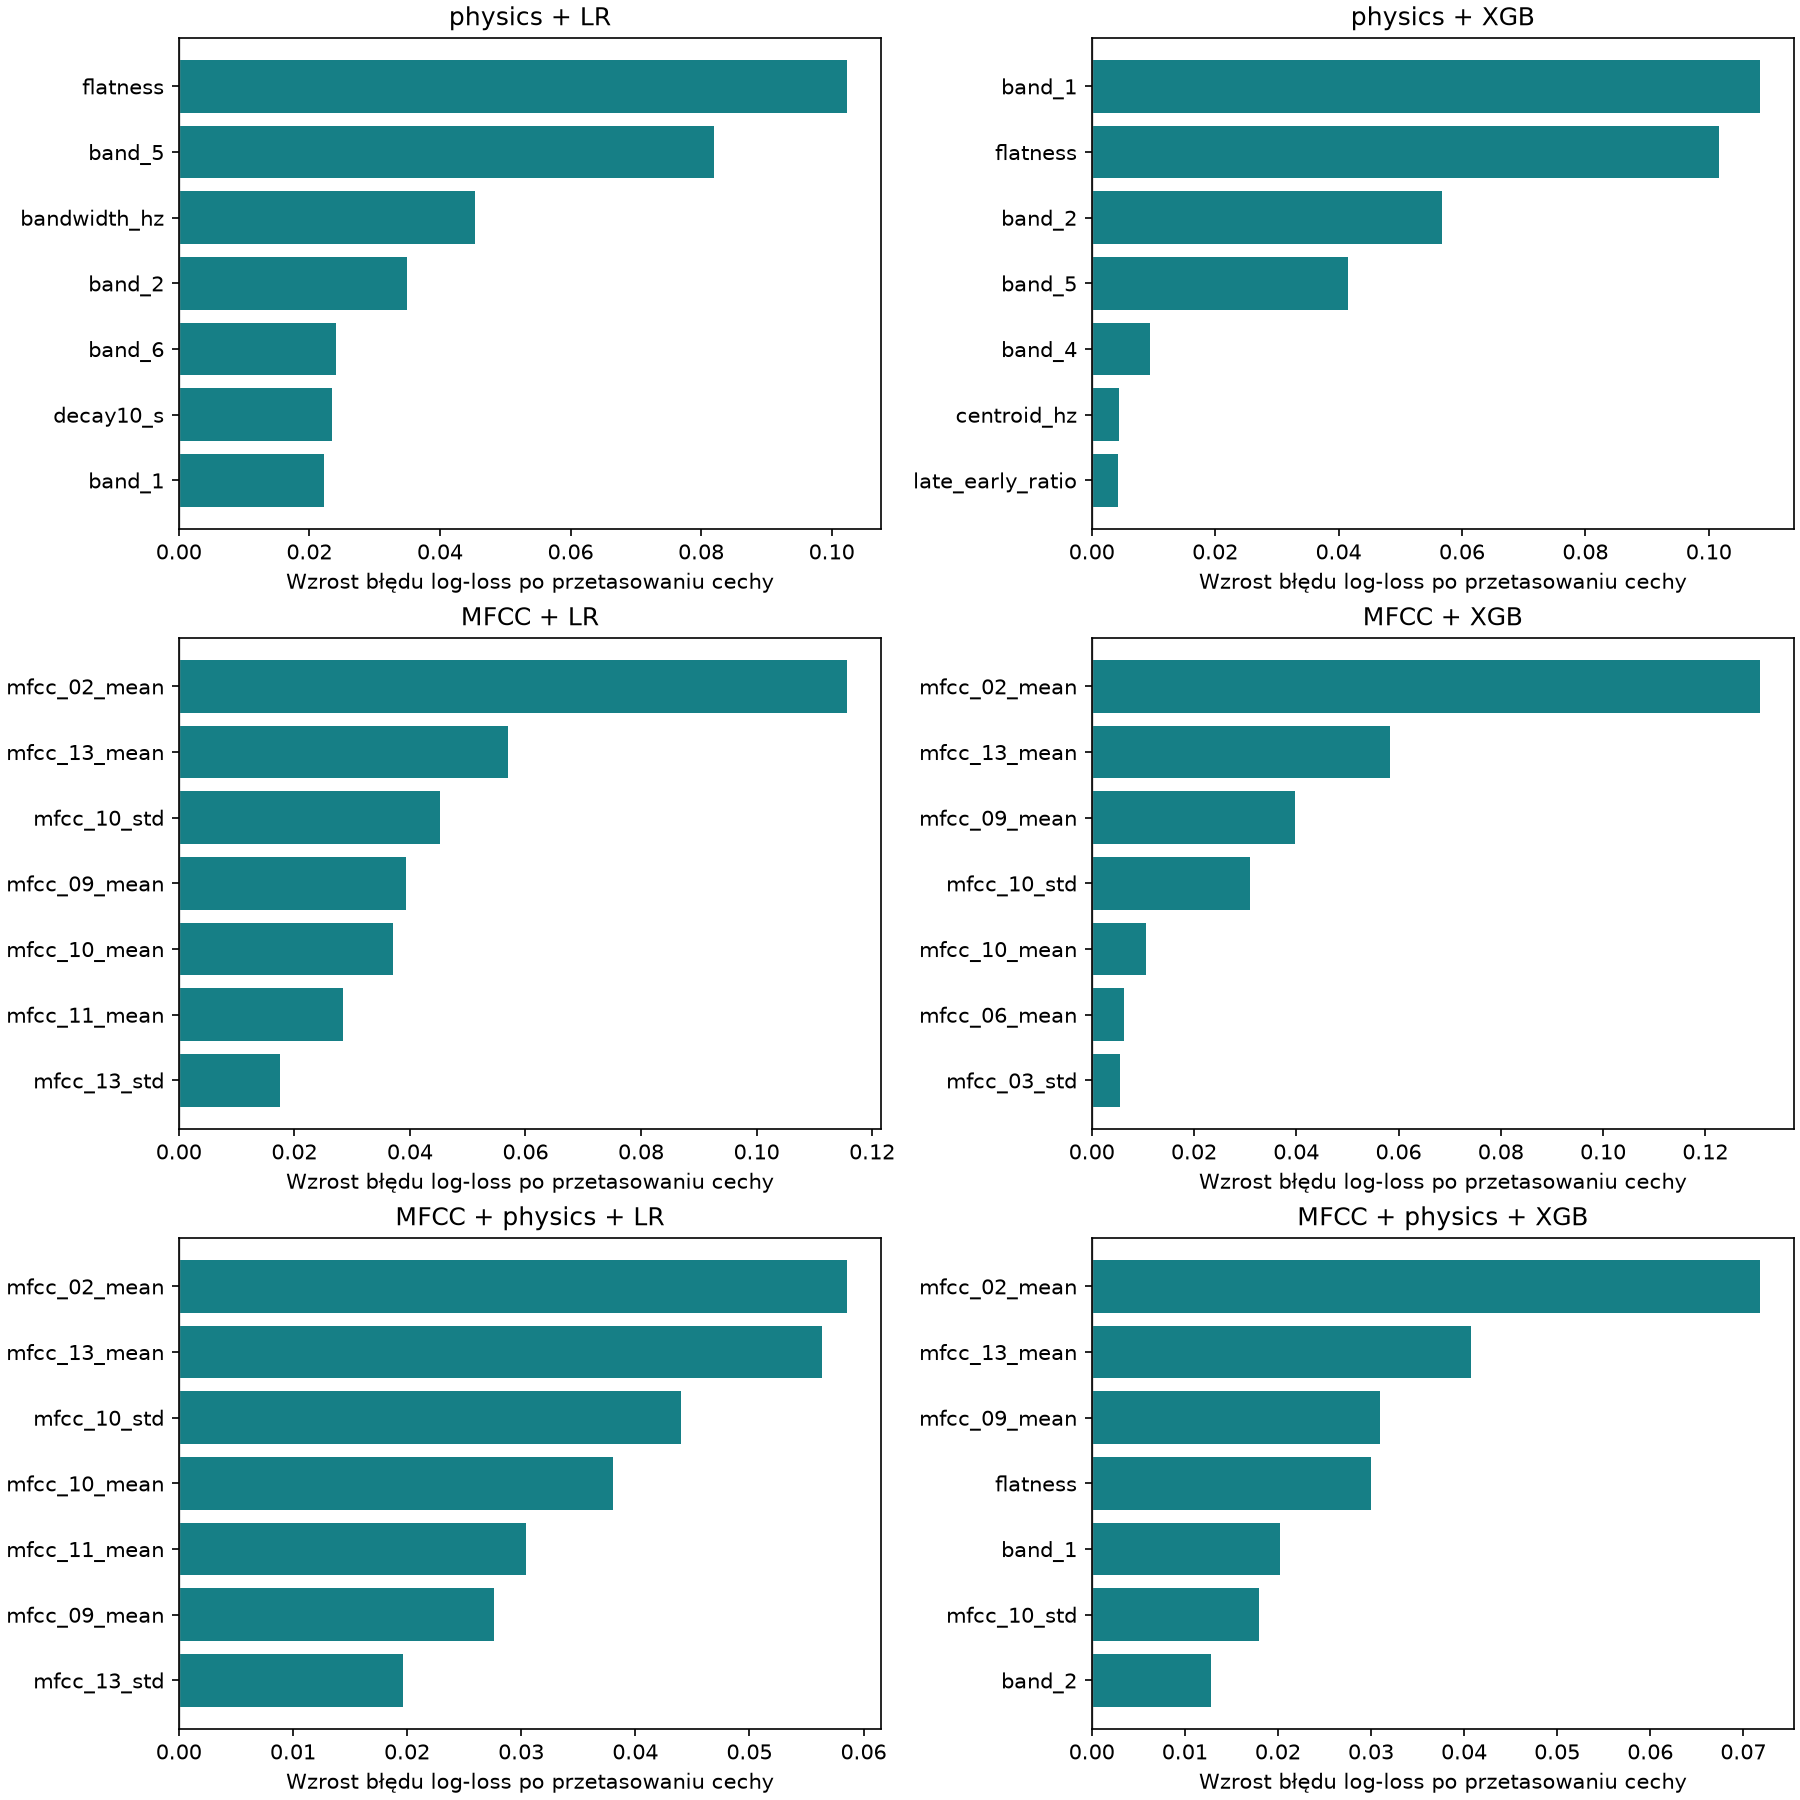

In [3]:
if RECOMPUTE or not (OUT/'feature_importance.csv').exists():
    importance = importances(ROOT, repeats=30)
else:
    importance = pd.read_csv(OUT/'feature_importance.csv')
display(Image(filename=str(OUT/'importance.png')))

## 3. Ranking i znaczenie nazw
Dla modeli łączonych pokazujemy również przetasowanie całej rodziny: ALL_mfcc i ALL_physics. To sprawdza wkład rodziny przy zachowaniu drugiej; pojedyncze skorelowane cechy mogą się zastępować.

MFCC_mean to średnia po ramkach wewnątrz uderzenia, MFCC_std — zmienność. Numer MFCC nie jest numerem pasma Hz. `flatness`: podobieństwo widma do równomiernego szumu; `band_1`: udział energii 80–201 Hz, `band_2`: 201–504 Hz, `band_5`: 3.18–7.97 kHz. W tabeli LR dodatnia waga przesuwa ocenę ku NOK, ujemna ku OK (przy pozostałych cechach stałych). Gain XGB nie ma takiego znaku. Nie porównuj wartości gain bezpośrednio z wagą regresji.

In [4]:
for name, g in importance.groupby('model'):
    display(Markdown('**'+name+'**'))
    display(g[~g.feature.str.startswith('ALL')].nlargest(7,'logloss_increase')[['feature','logloss_increase','ba_drop','positive_loss_folds','mean_abs_weight_or_gain','mean_signed_weight_or_gain']].round(3))
display(importance[importance.feature.str.startswith('ALL')][['model','feature','logloss_increase','ba_drop']].round(3))

**MFCC + LR**

,feature,logloss_increase,ba_drop,positive_loss_folds,mean_abs_weight_or_gain,mean_signed_weight_or_gain
5,mfcc_02_mean,0.116,0.121,6,0.699,0.699
27,mfcc_13_mean,0.057,0.047,6,0.529,-0.529
22,mfcc_10_std,0.045,0.017,6,0.432,-0.432
19,mfcc_09_mean,0.039,0.031,5,0.506,0.506
21,mfcc_10_mean,0.037,0.048,6,0.444,0.444
23,mfcc_11_mean,0.028,0.034,6,0.350,0.350
28,mfcc_13_std,0.018,0.008,6,0.284,-0.284


**MFCC + XGB**

,feature,logloss_increase,ba_drop,positive_loss_folds,mean_abs_weight_or_gain,mean_signed_weight_or_gain
34,mfcc_02_mean,0.131,0.208,6,0.139,0.139
56,mfcc_13_mean,0.058,0.067,6,0.078,0.078
48,mfcc_09_mean,0.040,0.066,6,0.092,0.092
51,mfcc_10_std,0.031,0.055,6,0.107,0.107
50,mfcc_10_mean,0.011,0.021,5,0.053,0.053
42,mfcc_06_mean,0.006,0.011,2,0.027,0.027
37,mfcc_03_std,0.005,-0.003,5,0.045,0.045


**MFCC + physics + LR**

,feature,logloss_increase,ba_drop,positive_loss_folds,mean_abs_weight_or_gain,mean_signed_weight_or_gain
75,mfcc_02_mean,0.059,0.041,6,0.518,0.518
97,mfcc_13_mean,0.056,0.061,6,0.483,-0.483
92,mfcc_10_std,0.044,0.028,6,0.420,-0.420
91,mfcc_10_mean,0.038,0.054,6,0.433,0.433
93,mfcc_11_mean,0.030,0.038,6,0.324,0.324
89,mfcc_09_mean,0.028,0.005,5,0.449,0.449
98,mfcc_13_std,0.020,-0.001,6,0.264,-0.264


... (3 outputs left out)

,feature,logloss_increase,ba_drop,positive_loss_folds,mean_abs_weight_or_gain,mean_signed_weight_or_gain
161,flatness,0.102,0.045,6,0.650,0.650
155,band_5,0.082,0.049,6,0.527,-0.527
157,bandwidth_hz,0.045,0.012,6,0.358,0.358
152,band_2,0.035,0.017,6,0.329,0.329
156,band_6,0.024,-0.001,5,0.281,0.281
159,decay10_s,0.023,-0.010,5,0.459,-0.459
151,band_1,0.022,0.003,5,0.307,0.307


**physics + XGB**

,feature,logloss_increase,ba_drop,positive_loss_folds,mean_abs_weight_or_gain,mean_signed_weight_or_gain
171,band_1,0.108,0.093,6,0.202,0.202
181,flatness,0.102,0.143,6,0.120,0.120
172,band_2,0.057,0.059,6,0.130,0.130
175,band_5,0.042,0.053,5,0.094,0.094
174,band_4,0.009,-0.004,5,0.085,0.085
178,centroid_hz,0.004,0.013,4,0.084,0.084
182,late_early_ratio,0.004,0.000,4,0.048,0.048


,model,feature,logloss_increase,ba_drop
0,MFCC + LR,ALL,0.961,0.485
1,MFCC + LR,ALL_means,0.532,0.357
2,MFCC + LR,ALL_stds,0.132,0.126
29,MFCC + XGB,ALL,0.376,0.455
30,MFCC + XGB,ALL_means,0.300,0.421
31,MFCC + XGB,ALL_stds,0.039,0.059
58,MFCC + physics + LR,ALL,1.020,0.466
59,MFCC + physics + LR,ALL_mfcc,0.733,0.411
60,MFCC + physics + LR,ALL_physics,0.071,0.046
102,MFCC + physics + XGB,ALL,0.376,0.472


## 4. Czy klasę można odgadnąć bez pingu?
To osobne modele uczone od początku. Pre-hit: −120…−20 ms, może zawierać poprzedni ogon. Quiet: do 5 najcichszych okien 100 ms, co najmniej 400 ms po wykryciu i 100 ms przed następnym. Nie ma takich fragmentów w R03/G01; pozostaje 25 plików. Okna mogą zawierać niewykryte dźwięki. Cyfrowa cisza jest reprezentowana jako brak sygnału, nie pomijana. Inne kontrole wycinają tylko 0–150, 0–60 lub 60–150 ms po pingu. Wszystkie zachowują podział po płytkach.

Control: pre_hit_100ms 270 windows 27 files
Control: quiet_100ms 118 windows 25 files
Control: no_pre_150ms 270 windows 27 files
Control: early_60ms 270 windows 27 files
Control: late_90ms 270 windows 27 files


,control,model,n,n_nok,accuracy,balanced_accuracy,recall_nok,false_reject_ok
0,pre_hit_100ms,MFCC + LR,27,9,0.889,0.889,0.889,0.111
1,pre_hit_100ms,MFCC + XGB,27,9,0.926,0.889,0.778,0.000
2,pre_hit_100ms,always OK,27,9,0.667,0.500,0.000,0.000
3,quiet_100ms,MFCC + LR,25,8,0.800,0.688,0.375,0.000
4,quiet_100ms,MFCC + XGB,25,8,0.880,0.812,0.625,0.000
5,quiet_100ms,always OK,25,8,0.680,0.500,0.000,0.000
6,no_pre_150ms,MFCC + LR,27,9,1.000,1.000,1.000,0.000
7,no_pre_150ms,MFCC + XGB,27,9,0.963,0.944,0.889,0.000
8,no_pre_150ms,always OK,27,9,0.667,0.500,0.000,0.000
9,early_60ms,MFCC + LR,27,9,0.963,0.972,1.000,0.056


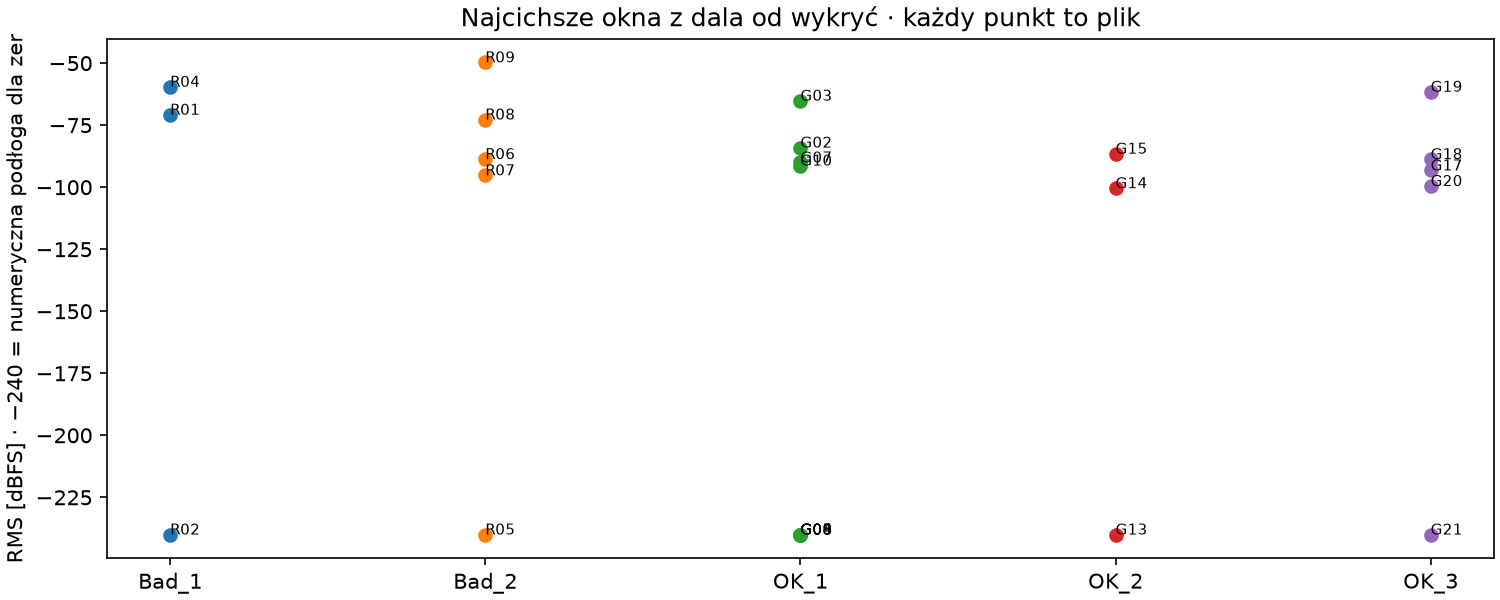

In [5]:
if RECOMPUTE or not (OUT/'control_results.csv').exists():
    results = controls(ROOT)
else:
    results = pd.read_csv(OUT/'control_results.csv')
display(results[['control','model','n','n_nok','accuracy','balanced_accuracy','recall_nok','false_reject_ok']].round(3))
display(Image(filename=str(OUT/'background_levels.png')))

## 5. Audyt fragmentów tła
Każdy wybrany fragment ma zapisane czasy. Poniżej po jednym oknie dwóch różnych plików; źródłowy poziom jest zachowany, więc może być niesłyszalny. Pełny odsłuch z przesuwaniem okna jest w notebooku 02. Sprawdź również, czy przed i po wybranym oknie nie ma pominiętego uderzenia.

In [6]:
audit = pd.read_csv(OUT/'quiet_window_audit.csv')
display(audit.groupby(['group','recording_id']).agg(okna=('event_id','size'),RMS_dBFS=('rms_dbfs','median'),zera=('zero_fraction','median')).round(3))
records, _, _ = load(ROOT)
for rid in ['R02','G06']:
    selected = audit[audit.recording_id.eq(rid)].iloc[0]
    r = records.set_index('recording_id').loc[rid]
    x, sr = decode(ROOT/r.path)
    z = x[round(selected.start_s*sr):round(selected.end_s*sr), int(r.selected_channel)]
    display(Markdown(f"**{rid}: {selected.start_s:.2f}–{selected.end_s:.2f} s**"))
    display(Audio(z,rate=sr,normalize=False))

okna  RMS_dBFS   zera
group recording_id                       
Bad_1 R01              5   -70.784  0.000
      R02              5  -240.000  1.000
      R04              2   -59.533  0.000
Bad_2 R05              5  -240.000  1.000
      R06              5   -88.683  0.000
      R07              5   -95.207  0.687
      R08              5   -72.723  0.057
      R09              5   -49.683  0.000
OK_1  G02              5   -84.028  0.226
      G03              5   -65.151  0.022
      G04              5  -240.000  1.000
      G05              5  -240.000  1.000
      G06              5  -240.000  1.000
      G07              5   -90.040  0.522
      G08              5  -240.000  1.000
      G09              5  -240.000  1.000
      G10              5   -91.280  0.436
OK_2  G13              5  -240.000  1.000
      G14              5  -100.400  0.902
      G15              5   -86.499  0.248
OK_3  G17              5   -93.242  0.561
      G18              5   -88.705  0.409
      G19              1   -61.530  0.016
      G20              5   -99.517  0.880
      G21              5  -240.000  1.000

**R02: 35.00–35.10 s**

**G06: 0.90–1.00 s**

## 6. Co z tego robimy?
**MFCC + regresja jako podstawowy kandydat, XGBoost jako porównanie.** Ranking nie jest dowodem, że model rozpoznaje pęknięcie. Nie wybieramy cech po obejrzeniu tych wyników i nie nazywamy kolejnego wyniku niezależnym testem.

Następny pomiar: te same ustawienia dla OK i NOK, naprzemiennie, 10 s tła przed/po, 10 tapów co 2–3 s. Powtórka po ustawieniu stanowiska od nowa. Model z pierwszej sesji testujemy na drugiej bez dostrajania, a potem na nowych fizycznych sztukach. Kontrola samego tła ma przestać zdradzać klasę.

In [7]:
import importlib.util
spec = importlib.util.spec_from_file_location('feature_review',ROOT/'scripts/build_feature_review.py')
review = importlib.util.module_from_spec(spec)
spec.loader.exec_module(review)
print('Raport:',review.write_report())
from datetime import datetime, timezone
(OUT/'last_run.json').write_text(json.dumps({'finished_utc':datetime.now(timezone.utc).isoformat(),'python':sys.executable,'recompute':RECOMPUTE},indent=2))
print('GOTOWE — cechy i tło: wszystkie komórki zakończone.')

Raport: /Users/karolsii/dev/ceramic-ping-lab/reports/runs/client-combined-20260929/explanations/START.html
GOTOWE — cechy i tło: wszystkie komórki zakończone.
